# Statistical analysis - Part 1

## Section 1: Two-sample comparisons (California dataset)

Author: Sneha Kumar (Questions or pull requests welcome)

1. Setup & splitting the dataset into two groups
    The purpose of this section is to divide the california dataset into two groups (records with fire occurence days and records with no fire occurence days) and eventually compare the means of predictor variables like: maximum temperature, minimum temperature, temperature range, precipitation, lagged precipitation, average windspeed, lagged average windspeed, and wind-tempoerature ratio, between the two data groups. We will also test the association between categorical variables: season, and fire occurence.

2. We establish a significance threshold of 0.05, and target power of 80% in these statistical tests.

In [ ]:
#importing necessary packages
import pandas as pd
import numpy as np
from statsmodels.stats.power import TTestIndPower
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
from IPython.display import display

#loading datasets and cleaning up missing values, and duplicate rows
df_cal = pd.read_csv('/Users/snehakumar/Documents/Work/SDSU/Fall 2026/STAT 520/Group_project/data/raw/CA_Weather_Fire_Dataset_1984-2025 (1).csv')
df_cal = df_cal.dropna()
df_cal = df_cal.drop_duplicates()
#confirming drop of missing values and duplicate rows
print("Missing values:")
print(df_cal.isnull().sum())
print("Duplicate rows:")
print(df_cal.duplicated().sum())

#splitting the dataset based on fire and no fire incidents
df_fire = df_cal[df_cal['FIRE_START_DAY'] == 1]
df_no_fire = df_cal[df_cal['FIRE_START_DAY'] == 0]

#Verifying the split by checking the number of rows in each dataset, and group summary statistics for each dataset
print("Number of rows in fire dataset:", len(df_fire))
print("Number of rows in no fire dataset:", len(df_no_fire))
print("Summary statistics for fire dataset:")
print(df_fire.describe())
print("Summary statistics for no fire dataset:")
print(df_no_fire.describe())

#exporting the cleaned dataset to a new CSV file for future analysis and modeling
df_cal.to_csv('/Users/snehakumar/Documents/Work/SDSU/Fall 2026/STAT 520/Group_project/data/processed/CA_Weather_Fire_Dataset_Cleaned.csv', index=False)


Missing values:
DATE                     0
PRECIPITATION            0
MAX_TEMP                 0
MIN_TEMP                 0
AVG_WIND_SPEED           0
FIRE_START_DAY           0
YEAR                     0
TEMP_RANGE               0
WIND_TEMP_RATIO          0
MONTH                    0
SEASON                   0
LAGGED_PRECIPITATION     0
LAGGED_AVG_WIND_SPEED    0
DAY_OF_YEAR              0
dtype: int64
Duplicate rows:
0
Number of rows in fire dataset: 4971
Number of rows in no fire dataset: 10005
Summary statistics for fire dataset:
       PRECIPITATION     MAX_TEMP     MIN_TEMP  AVG_WIND_SPEED         YEAR  \
count    4971.000000  4971.000000  4971.000000     4971.000000  4971.000000   
mean        0.002853    74.332327    60.990143        7.529423  2006.044458   
std         0.051172     6.254286     5.272886        1.616205    11.365000   
min         0.000000    56.000000    35.000000        2.240000  1984.000000   
25%         0.000000    70.000000    58.000000        6.710000  1

2. Power Analysis:
Performing power analysis to determine of the sample size in hand is adequate for a given effect size benchmark (small d = 0.20, moderate d = 0.50, large d = 0.80).

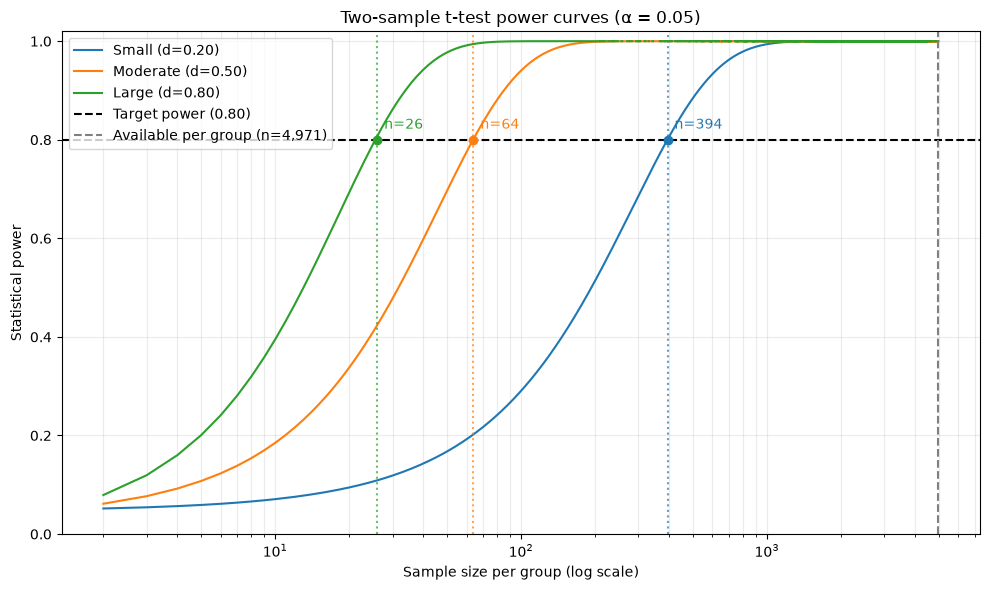

In [3]:
# Two-sided independent-samples t-test, equal group sizes
alpha = 0.05
target_power = 0.80
effect_sizes = {"Small (d=0.20)": 0.20, "Moderate (d=0.50)": 0.50, "Large (d=0.80)": 0.80}

power_analysis = TTestIndPower()
max_n = min(len(df_fire), len(df_no_fire))
sample_sizes = np.arange(2, max_n + 1)

fig, ax = plt.subplots(figsize=(10, 6))

for label, effect_size in effect_sizes.items():
    required_n = int(np.ceil(
        power_analysis.solve_power(
            effect_size=effect_size,
            power=target_power,
            alpha=alpha,
            ratio=1,
            alternative="two-sided"
        )
    ))

    powers = power_analysis.power(
        effect_size=effect_size,
        nobs1=sample_sizes,
        alpha=alpha,
        ratio=1,
        alternative="two-sided"
    )
    line, = ax.plot(sample_sizes, powers, label=label)
    ax.scatter(required_n, target_power, color=line.get_color(), zorder=3)
    ax.axvline(required_n, color=line.get_color(), linestyle=":", alpha=0.7)
    ax.annotate(
        f"n={required_n}",
        (required_n, target_power),
        xytext=(5, 8),
        textcoords="offset points",
        color=line.get_color()
    )

ax.axhline(target_power, color="black", linestyle="--", label="Target power (0.80)")
ax.axvline(max_n, color="gray", linestyle="--",
           label=f"Available per group (n={max_n:,})")

ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Sample size per group (log scale)")
ax.set_ylabel("Statistical power")
ax.set_title("Two-sample t-test power curves (α = 0.05)")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()  

Power analysis conclusion:
* It is apparent from the power analysis that the following sample sizes are required to detect these effect sizes:
    * Large effect (d=0.8) = 26
    * Moderate effect (d = 0.50) = 64
    * Small effect (d = 0.20) = 394
* Since our limiting group (fire group), i.e., having the smaller number of observations (4971) is higher than 394, we are equipped to detect small effects, giving us nearly 100% statistical power.

3. Two-sample testing for the following variables in the Calfornia dataset:
    * Maximum temperature
    * Minimum temperature 
    * Temperature range
    * Precipitation
    * Lagged precipitation
    * Average windspeed
    * Lagged average windspeed
    * Wind-tempoerature ratio

In [4]:
#Creating a class to perform two-sample analysis for each variable in the dataset, including descriptive statistics, variance homogeneity checks, parametric and non-parametric tests, effect size calculation, and visualization of results.
class TwoSampleAnalyzer:
    def __init__(self, df, group_col="FIRE_START_DAY", fire_val=True, no_fire_val=False, alpha=0.05):
        self.df = df
        self.group_col = group_col
        self.fire_val = fire_val
        self.no_fire_val = no_fire_val
        self.alpha = alpha
        self.results = []

    def analyze(self, var, label=None, unit="", plot=True):
        label = label or var
        sub = self.df[[self.group_col, var]].dropna()
        
        g_fire = sub.loc[sub[self.group_col] == self.fire_val, var]
        g_nofire = sub.loc[sub[self.group_col] == self.no_fire_val, var]
        
        # 1. Descriptive stats
        mean_f, sd_f, med_f, iqr_f = g_fire.mean(), g_fire.std(), g_fire.median(), g_fire.quantile(0.75) - g_fire.quantile(0.25)
        mean_nf, sd_nf, med_nf, iqr_nf = g_nofire.mean(), g_nofire.std(), g_nofire.median(), g_nofire.quantile(0.75) - g_nofire.quantile(0.25)
        mean_diff = mean_f - mean_nf
        
        # 2. Variance homogeneity checks (Bartlett vs. robust Fligner-Killeen)
        bart_p = stats.bartlett(g_fire, g_nofire).pvalue
        flig_p = stats.fligner(g_fire, g_nofire).pvalue
        
        # 3. Parametric: Welch's 2-sample t-test + 95% CI
        welch = stats.ttest_ind(g_fire, g_nofire, equal_var=False)
        cm = CompareMeans(DescrStatsW(g_fire), DescrStatsW(g_nofire))
        ci_low, ci_high = cm.tconfint_diff(usevar="unequal")
        
        # 4. Non-parametric: Mann-Whitney U test
        mwu = stats.mannwhitneyu(g_fire, g_nofire, alternative="two-sided")
        
        # 5. Standardized effect size (Cohen's d using pooled SD)
        n1, n2 = len(g_fire), len(g_nofire)
        pooled_sd = np.sqrt(((n1 - 1)*sd_f**2 + (n2 - 1)*sd_nf**2) / (n1 + n2 - 2))
        cohens_d = mean_diff / pooled_sd if pooled_sd > 0 else np.nan
        
        # 6. Decisions & Agreement
        param_sig = welch.pvalue <= self.alpha
        nonparam_sig = mwu.pvalue <= self.alpha
        agree = "Agree (Both Reject H0)" if (param_sig and nonparam_sig) else (
                "Agree (Both Fail to Reject)" if (not param_sig and not nonparam_sig) else "Diverge")
        
        # Store for master summary table
        row = {
            "Variable": var,
            "Fire Mean (SD)": f"{mean_f:.2f} ({sd_f:.2f})",
            "No-Fire Mean (SD)": f"{mean_nf:.2f} ({sd_nf:.2f})",
            "Mean Diff": round(mean_diff, 3),
            "95% CI": f"({ci_low:.3f}, {ci_high:.3f})",
            "Fire Median (IQR)": f"{med_f:.2f} ({iqr_f:.2f})",
            "No-Fire Median (IQR)": f"{med_nf:.2f} ({iqr_nf:.2f})",
            "Bartlett p": round(bart_p, 4),
            "Fligner-Killeen p": round(flig_p, 4),
            "Welch t": round(welch.statistic, 3),
            "Welch p": round(welch.pvalue, 5),
            "MWU p": round(mwu.pvalue, 5),
            "Cohen's d": round(cohens_d, 3),
            "Agreement": agree
        }
        # Avoid duplicates if you re-run a cell
        self.results = [r for r in self.results if r["Variable"] != var]
        self.results.append(row)
        
        # Minimalist single-variable output card
        display(pd.DataFrame([row]).set_index("Variable"))
        
        # Compact 1x3 diagnostic figure (Violin+Box, Q-Q Fire, Q-Q No-Fire)
        if plot:
            fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
            
            sns.violinplot(
                data=sub, x=self.group_col, y=var, ax=axes[0],
                inner="box", palette=["#4DBBD5", "#E64B35"], hue=self.group_col, legend=False
            )
            axes[0].set_title(f"{label} by Group")
            axes[0].set_xlabel("")
            axes[0].set_xticks([0, 1], labels=["No-Fire", "Fire"])
            axes[0].set_ylabel(f"{label} ({unit})" if unit else label)
            
            qqplot(g_fire, line="s", ax=axes[1], markerfacecolor="#E64B35", markeredgecolor="#E64B35", alpha=0.5)
            axes[1].set_title(f"Q-Q Plot: Fire Days (n={n1})")
            
            qqplot(g_nofire, line="s", ax=axes[2], markerfacecolor="#4DBBD5", markeredgecolor="#4DBBD5", alpha=0.5)
            axes[2].set_title(f"Q-Q Plot: No-Fire Days (n={n2})")
            
            plt.tight_layout()
            plt.show()

    def summary_table(self):
        return pd.DataFrame(self.results).set_index("Variable")

analyzer = TwoSampleAnalyzer(df_cal, group_col="FIRE_START_DAY")

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
MAX_TEMP,74.33 (6.25),68.66 (6.99),5.675,"(5.454, 5.896)",74.00 (7.00),68.00 (9.00),0.0,0.0,50.264,0.0,0.0,0.84,Agree (Both Reject H0)


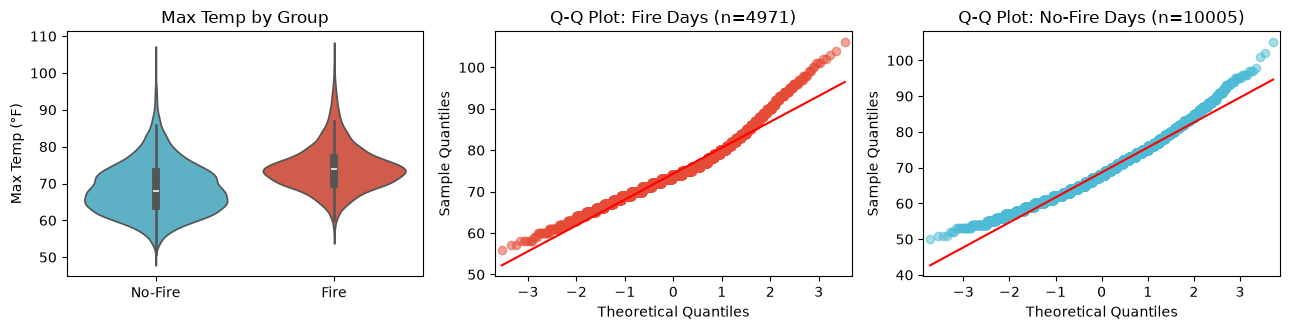

In [5]:
#3A. Comparing maximum temperature between fire and no-fire days
analyzer.analyze("MAX_TEMP", label="Max Temp", unit="°F")

**Interpretation (`MAX_TEMP`):**
* **Distributional & Variance Checks:** Both groups are roughly bell-shaped on the Q-Q plots with mild upper-tail departure, and variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner-Killeen $p < 0.0001$; $\text{SD} = 6.25^\circ\text{F}$ vs. $6.99^\circ\text{F}$), supporting Welch's unequal-variance $t$-test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = 50.264, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a mean maximum temperature $5.68^\circ\text{F}$ higher than non-fire days ($74.33^\circ\text{F}$ vs. $68.66^\circ\text{F}$; $95\%$ CI: $[5.45^\circ\text{F}, 5.90^\circ\text{F}]$) with a **large effect size (Cohen's $d = 0.84$)**, indicating a practically meaningful shift in daily peak heat on wildfire ignition days.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
MIN_TEMP,60.99 (5.27),54.27 (6.30),6.722,"(6.530, 6.913)",62.00 (6.00),54.00 (9.00),0.0,0.0,68.735,0.0,0.0,1.124,Agree (Both Reject H0)


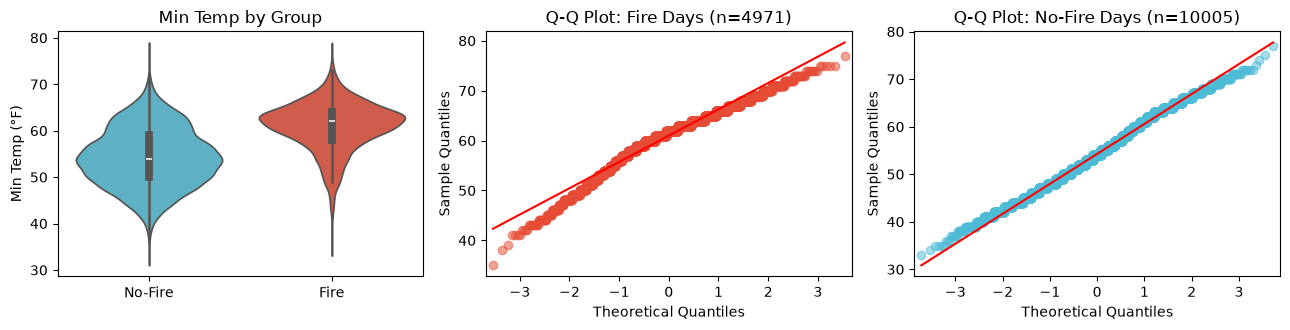

In [6]:
#3B. Comparing minimum temperature between fire and no-fire days
analyzer.analyze("MIN_TEMP", label="Min Temp", unit="°F")

**Interpretation (`MIN_TEMP`):**
* **Distributional & Variance Checks:** Both groups appear roughly bell-shaped through the middle quantiles on the Q-Q plots with mild tail departures (lower tail on fire days, slight upper tail on no-fire days), and variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 5.27^\circ\text{F}$ vs. $6.30^\circ\text{F}$), supporting Welch's unequal-variance $t$-test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = 68.735, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a mean minimum temperature $6.72^\circ\text{F}$ higher than non-fire days ($60.99^\circ\text{F}$ vs. $54.27^\circ\text{F}$; $95\%$ CI: $[6.530^\circ\text{F}, 6.913^\circ\text{F}]$; medians $62.00^\circ\text{F}$ vs. $54.00^\circ\text{F}$) with a **large effect size (Cohen's $d = 1.124$)**, indicating substantially warmer overnight/minimum temperatures on wildfire ignition days.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
TEMP_RANGE,13.34 (5.71),14.39 (6.11),-1.046,"(-1.245, -0.848)",12.00 (5.00),13.00 (8.00),0.0,0.0,-10.322,0.0,0.0,-0.175,Agree (Both Reject H0)


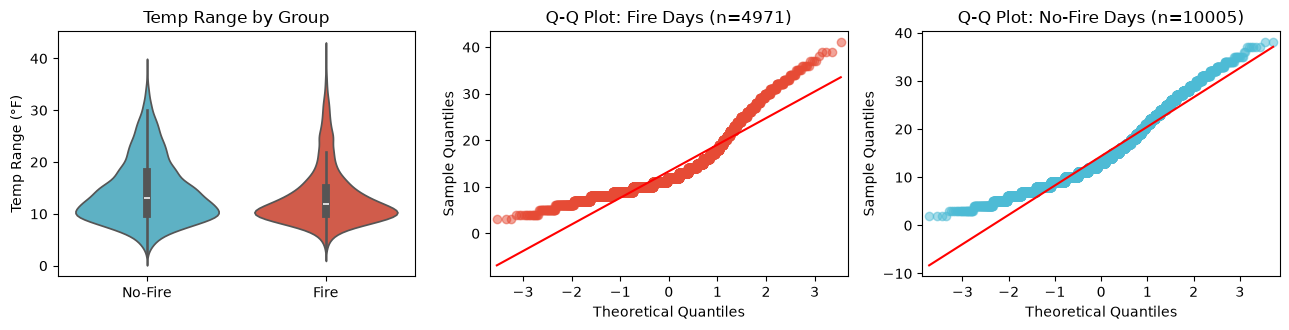

In [7]:
#3C. Comparing temperature range between fire and no-fire days  
analyzer.analyze("TEMP_RANGE", label="Temp Range", unit="°F")

**Interpretation (`TEMP_RANGE`):**
* **Distributional & Variance Checks:** Both groups show departures from normality on the Q-Q plots (particularly upward curvature in the upper quantiles / wider daily temperature swings, with some low/near-zero values in the lower tail), and variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 5.71^\circ\text{F}$ vs. $6.11^\circ\text{F}$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = -10.322, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a slightly smaller mean diurnal temperature range than non-fire days by $-1.046^\circ\text{F}$ ($13.34^\circ\text{F}$ vs. $14.39^\circ\text{F}$; $95\%$ CI: $[-1.245^\circ\text{F}, -0.848^\circ\text{F}]$; medians $12.00^\circ\text{F}$ vs. $13.00^\circ\text{F}$), corresponding to a **small negative effect size (Cohen's $d = -0.175$)**. Although statistically significant given the large sample sizes, the roughly $1^\circ\text{F}$ difference is modest in practical terms—and because `TEMP_RANGE` is derived from `MAX_TEMP` and `MIN_TEMP`, it is set aside in favor of more direct/non-redundant predictors for multiple logistic regression.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
PRECIPITATION,0.00 (0.05),0.05 (0.22),-0.044,"(-0.049, -0.040)",0.00 (0.00),0.00 (0.00),0.0,0.0,-19.433,0.0,0.0,-0.247,Agree (Both Reject H0)


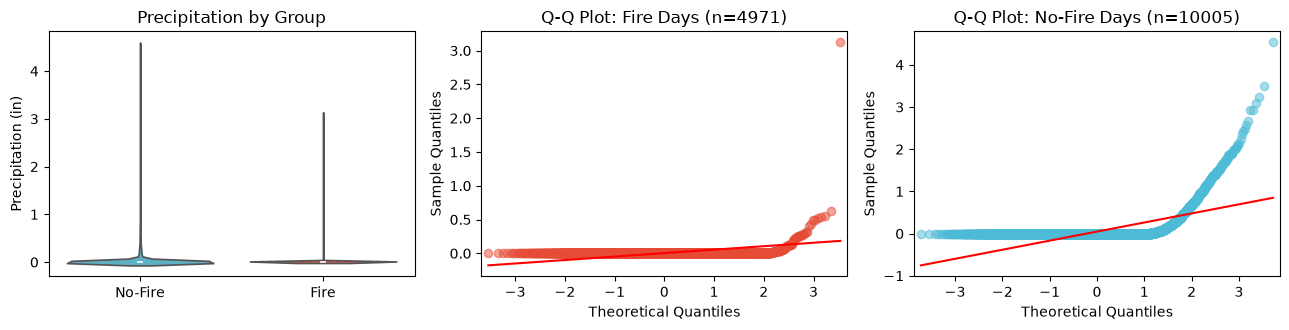

In [8]:
#3D. Comparing precipitation between fire and no-fire days
analyzer.analyze("PRECIPITATION", label="Precipitation", unit="in")

**Interpretation (`PRECIPITATION`):**
* **Distributional & Variance Checks:** Both groups are heavily zero-inflated and right-skewed on the Q-Q and violin plots (with medians and IQRs of `0.00 (0.00)` in both groups, and extreme rainfall outliers extending above `3.0–4.5 in`), while variance tests indicate unequal spreads between groups (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 0.05\text{ in}$ vs. $0.22\text{ in}$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = -19.433, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a slightly lower mean daily precipitation than non-fire days by $-0.044\text{ in}$ (`0.00 in` vs. `0.05 in` rounded to two decimals; $95\%$ CI: $[-0.049\text{ in}, -0.040\text{ in}]$), corresponding to a **small-to-moderate negative effect size (Cohen's $d = -0.247$)**. While both groups are mostly dry on a given day, non-fire days experience slightly higher average and occasional heavy rainfall events, making precipitation (alongside multi-day lagged precipitation) a relevant moisture factor to examine further.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
LAGGED_PRECIPITATION,0.03 (0.18),0.32 (0.76),-0.295,"(-0.311, -0.280)",0.00 (0.00),0.00 (0.24),0.0,0.0,-36.574,0.0,0.0,-0.466,Agree (Both Reject H0)


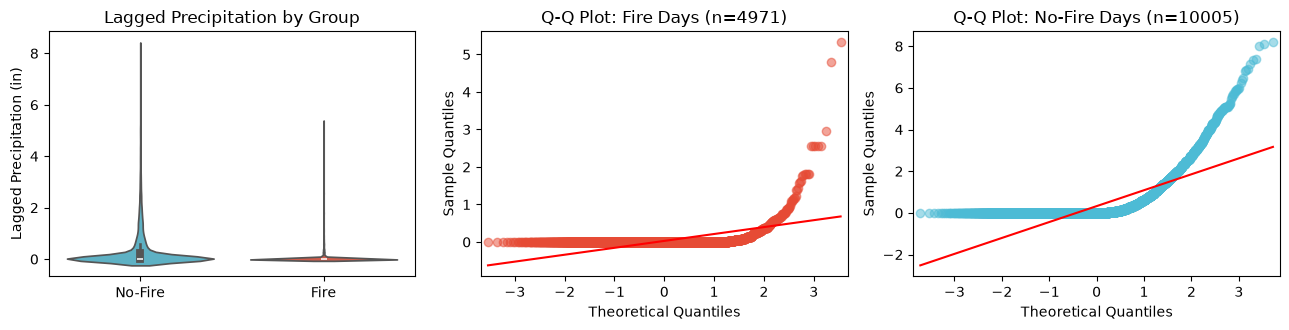

In [9]:
#3E. Comparing lagged precipitation between fire and no-fire days
analyzer.analyze("LAGGED_PRECIPITATION", label="Lagged Precipitation", unit="in")

**Interpretation (`LAGGED_PRECIPITATION`):**
* **Distributional & Variance Checks:** Both groups are strongly right-skewed and zero-inflated on the violin and Q-Q plots (medians of `0.00 in` in both groups, with $\text{IQR} = 0.00\text{ in}$ for fire days vs. `0.24 in` for non-fire days, and multi-inch cumulative rainfall tails extending up to ~`8 in`), while variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 0.18\text{ in}$ vs. $0.76\text{ in}$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = -36.574, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a lower mean 7-day cumulative lagged precipitation than non-fire days by $-0.295\text{ in}$ (`0.03 in` vs. `0.32 in`; $95\%$ CI: $[-0.311\text{ in}, -0.280\text{ in}]$), corresponding to a **small-to-moderate negative effect size (Cohen's $d = -0.466$)**. This captures noticeably drier antecedent multi-day moisture conditions prior to wildfire ignition days, making `LAGGED_PRECIPITATION` a meaningful moisture predictor alongside immediate daily `PRECIPITATION`.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
AVG_WIND_SPEED,7.53 (1.62),7.39 (2.34),0.141,"(0.077, 0.205)",7.61 (1.79),6.93 (2.68),0.0,0.0,4.308,0.00002,0.0,0.066,Agree (Both Reject H0)


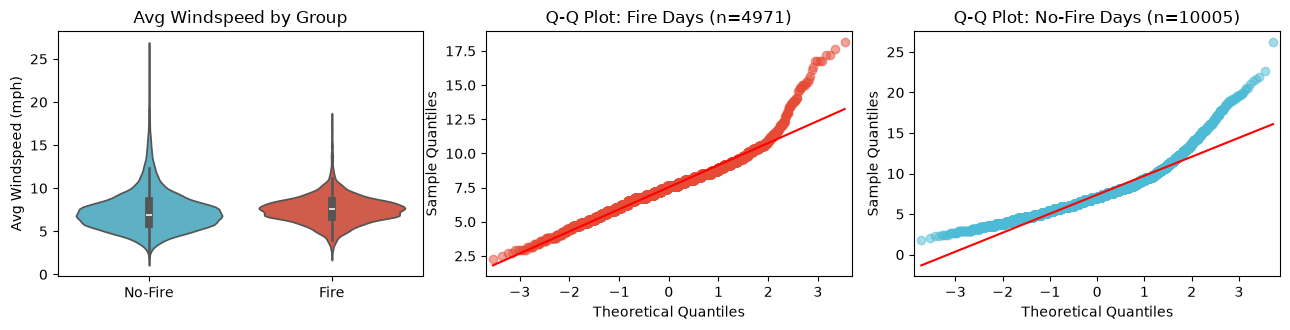

In [10]:
#3F. Comparing average windspeed between fire and no-fire days
analyzer.analyze("AVG_WIND_SPEED", label="Avg Windspeed", unit="mph")

**Interpretation (`AVG_WIND_SPEED`):**
* **Distributional & Variance Checks:** Both groups show departures from normality on the Q-Q plots (particularly upward tail curvature at higher wind speeds on fire days and lower/upper tail departures on no-fire days), while variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 1.62\text{ mph}$ vs. $2.34\text{ mph}$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = 4.308, p = 0.00002$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a slightly higher mean daily wind speed than non-fire days by $+0.141\text{ mph}$ (`7.53 mph` vs. `7.39 mph`; $95\%$ CI: $[0.077\text{ mph}, 0.205\text{ mph}]$; medians `7.61 mph` vs. `6.93 mph`), corresponding to a **very small positive effect size (Cohen's $d = 0.066$)**. While statistically significant due to the large sample sizes, the average daily mean wind speed shift is small on its own—making it useful to examine alongside 7-day lagged wind speed (`LAGGED_AVG_WIND_SPEED`) and in multivariable modeling.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
LAGGED_AVG_WIND_SPEED,7.59 (1.11),7.36 (1.50),0.228,"(0.186, 0.271)",7.64 (1.31),7.35 (2.01),0.0,0.0,10.492,0.0,0.0,0.165,Agree (Both Reject H0)


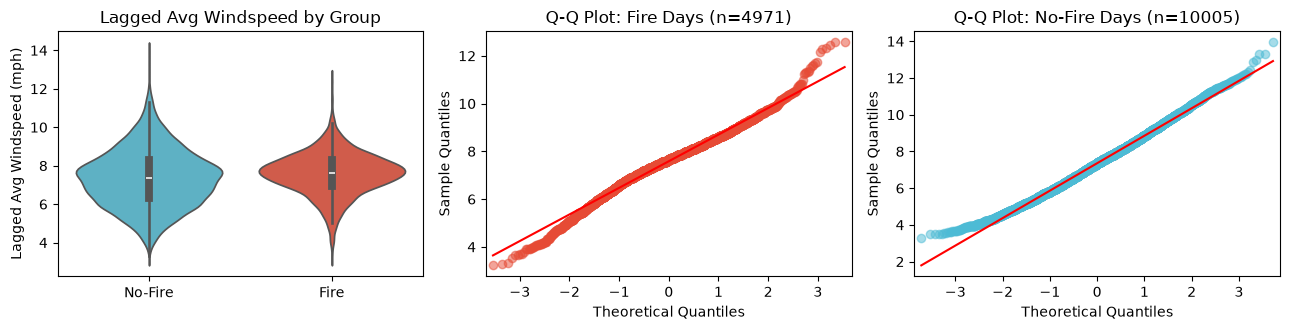

In [11]:
#3G. Comparing lagged average windspeed between fire and no-fire days
analyzer.analyze("LAGGED_AVG_WIND_SPEED", label="Lagged Avg Windspeed", unit="mph")

**Interpretation (`LAGGED_AVG_WIND_SPEED`):**
* **Distributional & Variance Checks:** Both groups show departures from normality on the Q-Q plots (particularly upward tail curvature at higher sustained wind speeds and lower-tail deviations), while variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 1.11\text{ mph}$ vs. $1.50\text{ mph}$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = 10.492, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a slightly higher mean 7-day lagged wind speed than non-fire days by $+0.228\text{ mph}$ (`7.59 mph` vs. `7.36 mph`; $95\%$ CI: $[0.186\text{ mph}, 0.271\text{ mph}]$; medians `7.64 mph` vs. `7.35 mph`), corresponding to a **small positive effect size (Cohen's $d = 0.165$)**. Although statistically significant given the large sample sizes, the average multi-day wind speed shift is modest on its own—making it useful alongside immediate `AVG_WIND_SPEED` and in multivariable modeling to see how sustained wind interacts with temperature and moisture.

,Fire Mean (SD),No-Fire Mean (SD),Mean Diff,95% CI,Fire Median (IQR),No-Fire Median (IQR),Bartlett p,Fligner-Killeen p,Welch t,Welch p,MWU p,Cohen's d,Agreement
Variable,,,,,,,,,,,,,
WIND_TEMP_RATIO,0.10 (0.03),0.11 (0.04),-0.007,"(-0.008, -0.006)",0.10 (0.03),0.10 (0.04),0.0,0.0,-13.306,0.0,0.0,-0.2,Agree (Both Reject H0)


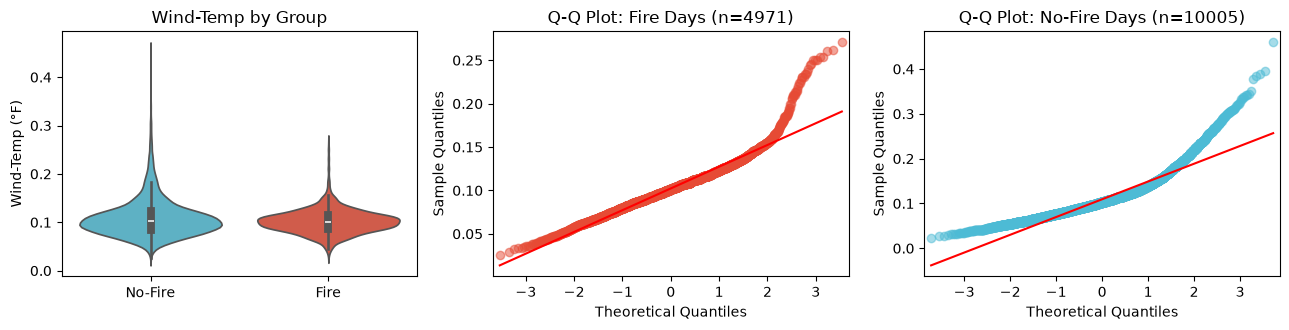

In [12]:
#3H. Comparing wind-temperature between fire and no-fire days
analyzer.analyze("WIND_TEMP_RATIO", label="Wind-Temp", unit="°F")

**Interpretation (`WIND_TEMP_RATIO`):**
* **Distributional & Variance Checks:** Both groups show departures from normality on the Q-Q plots (particularly upward tail curvature at higher ratio values and lower-tail deviations), while variance tests indicate unequal group spreads (Bartlett $p < 0.0001$, Fligner–Killeen $p < 0.0001$; $\text{SD} = 0.03$ vs. $0.04$), supporting Welch's unequal-variance $t$-test alongside the rank-based Mann–Whitney U test.
* **Hypothesis Test Results:** Welch's two-sample $t$-test ($t = -13.306, p < 0.0001$) and the non-parametric Mann–Whitney U test ($p < 0.0001$) both reject $H_0$ at $\alpha = 0.05$, showing full parametric and non-parametric agreement.
* **Practical Significance:** Fire start days have a slightly lower mean wind-to-temperature ratio than non-fire days by $-0.007$ (`0.10` vs. `0.11`; $95\%$ CI: $[-0.008, -0.006]$; medians `0.10` in both groups with $\text{IQR} = 0.03$ vs. `0.04`), corresponding to a **small negative effect size (Cohen's $d = -0.20$)**. Although statistically significant given the large sample sizes, the shift is small in practical terms—and because `WIND_TEMP_RATIO` is derived from `AVG_WIND_SPEED` and `MAX_TEMP`, we set it aside in favor of direct, non-redundant predictors in our multiple logistic regression model.

In [13]:
#testing chi squared test of independence between variables: season and fire_start_day

contingency_table = pd.crosstab(df_cal['SEASON'], df_cal['FIRE_START_DAY'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print("Chi-squared test of independence between SEASON and FIRE_START_DAY:")
print(f"Chi-squared statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi-squared test of independence between SEASON and FIRE_START_DAY:
Chi-squared statistic: 3478.8431
Degrees of freedom: 3
P-value: 0.0000


**Interpretation (`SEASON` vs. `FIRE_START_DAY` — Chi-Square Test of Independence):**
* **Hypothesis Test Results:** The Pearson chi-square test of independence yields $\chi^2 = 3478.8431$ with $\text{df} = 3$ and $p < 0.0001$ (`0.0000` rounded to four decimals), rejecting the null hypothesis ($H_0$) of independence at $\alpha = 0.05$.
* **Practical & Analytical Takeaway:** Wildfire start day occurrence is strongly associated with calendar season across the four seasons ($\text{df} = 3$), confirming that seasonal timing is an important categorical predictor to include in the multiple logistic regression model.

### Conclusions from two population testing
* MAX_TEMP (Maximum Daily Temperature): Fire start days are significantly warmer by $+5.68^\circ\text{F}$ ($74.33^\circ\text{F}$ vs. $68.66^\circ\text{F}$; $p < 0.0001$), with full parametric/non-parametric agreement and a large practical effect ($d = 0.84$).
* MIN_TEMP (Minimum Daily Temperature): Fire start days have significantly higher overnight minimum temperatures by $+6.72^\circ\text{F}$ ($60.99^\circ\text{F}$ vs. $54.27^\circ\text{F}$; $p < 0.0001$), showing full test agreement and the largest effect size ($d = 1.124$).
* TEMP_RANGE (Diurnal Temperature Range): Fire start days show a slightly narrower daily temperature swing by $-1.05^\circ\text{F}$ ($13.34^\circ\text{F}$ vs. $14.39^\circ\text{F}$; $p < 0.0001$), with a small effect size ($d = -0.175$); excluded from regression to avoid redundancy with MAX_TEMP and MIN_TEMP.* PRECIPITATION (Daily Precipitation): Fire start days have slightly lower mean daily rainfall by $-0.044\text{ in}$ (0.00 in vs. 0.05 in; $p < 0.0001$), with full test agreement and a small-to-moderate effect ($d = -0.247$).
* LAGGED_PRECIPITATION (7-Day Cumulative Precipitation Lag): Fire start days follow noticeably drier 7-day windows by $-0.295\text{ in}$ (0.03 in vs. 0.32 in; $p < 0.0001$), with full test agreement and a moderate practical effect ($d = -0.466$).
* AVG_WIND_SPEED (Average Daily Wind Speed): Fire start days show a slightly higher mean wind speed by $+0.141\text{ mph}$ (7.53 mph vs. 7.39 mph; $p = 0.00002$), with full test agreement but a very small standalone effect ($d = 0.066$).
* LAGGED_AVG_WIND_SPEED (7-Day Average Wind Speed Lag): Fire start days follow slightly windier 7-day periods by $+0.228\text{ mph}$ (7.59 mph vs. 7.36 mph; $p < 0.0001$), with full test agreement and a small effect ($d = 0.165$).
* WIND_TEMP_RATIO (Wind-to-Temperature Ratio): Fire start days have a slightly lower ratio by $-0.007$ (0.10 vs. 0.11; $p < 0.0001$), with a small effect ($d = -0.20$); set aside for regression to avoid collinearity with raw wind and temperature features.SEASON (Categorical Association): Strongly associated with wildfire start days ($\chi^2 = 3478.8431, \text{df} = 3, p < 0.0001$), confirming seasonal timing as a key categorical predictor.  

**Multiple Testing Note (FWER / Bonferroni):** Because multiple two-sample comparisons were conducted across weather variables between fire and no-fire days, family-wise Type I error inflation ($\text{FWER}$) is a consideration when testing multiple hypotheses. Applying a conservative Bonferroni adjustment ($\alpha^* = \alpha / m$) tightens the per-test threshold, though it can reduce power. All tested variables already show very small $p$-values well below standard Bonferroni-adjusted thresholds, so conclusions rely primarily on **95% confidence intervals, effect sizes (Cohen's $d$), and practical significance** rather than $p$-values alone.

**Next Step — Multivariable & Predictive Modeling (`Modeling_Logistic_and_ML.ipynb`):**
Having established individual group differences and practical effect sizes across our weather and seasonal predictors, the next notebook evaluates their joint effects and predictive performance using:
1. **Multiple Logistic Regression:** Modeling the log-odds and odds ratios of `FIRE_START_DAY` using a non-redundant predictor set (`MAX_TEMP`, `AVG_WIND_SPEED`, `PRECIPITATION`, `LAGGED_PRECIPITATION`, `LAGGED_AVG_WIND_SPEED`, dummy-coded `SEASON`, and `YEAR`) after checking Variance Inflation Factors (VIF).
2. **Random Forest Classifier (Two-Phase Design):** Training and evaluating a non-linear ensemble model on the California dataset (Phase 1), then testing its external validity and generalizability on the Global Wildfire Dataset (Phase 2).